# Day 5 (Task 2, first version): Regression with Scikit-learn

Predict house price (million PKR) from the house features. Models are compared on the
**validation** set. The test set stays untouched until Day 7.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split

df = pd.read_csv("houses_clean.csv")

# one-hot encode the zone column (drop one level so the columns are not redundant)
df = pd.get_dummies(df, columns=["location_zone"], drop_first=True, dtype=int)

# same 70 / 15 / 15 split as Day 4
train, temp = train_test_split(df, test_size=0.30, random_state=42)
val, test = train_test_split(temp, test_size=0.50, random_state=42)
print(len(train), len(val), len(test))
df.head()

207 45 45


,area_marla,bedrooms,bathrooms,age_years,price_million_pkr,location_zone_Outskirts,location_zone_Suburban
0,12.5,5,5,11,23.58,0,0
1,5.5,1,1,14,5.05,1,0
2,10.5,3,2,15,16.35,0,0
3,18.5,4,3,23,23.27,0,1
4,11.5,3,2,22,15.20,0,1


## 1. Simple linear regression: price from area only
Model: `price = b0 + b1 * area`.

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

def report(name, y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    print(f"{name:28s} MAE={mean_absolute_error(y_true, y_pred):.3f}  "
          f"RMSE={mse ** 0.5:.3f}  R2={r2_score(y_true, y_pred):.3f}")

simple = LinearRegression()
simple.fit(train[["area_marla"]], train["price_million_pkr"])

print(f"price = {simple.intercept_:.2f} + {simple.coef_[0]:.2f} * area")
report("Simple (area only)", val["price_million_pkr"], simple.predict(val[["area_marla"]]))

# sanity check: NumPy's least squares line should match
slope, intercept = np.polyfit(train["area_marla"], train["price_million_pkr"], 1)
print(f"np.polyfit check            : price = {intercept:.2f} + {slope:.2f} * area")

price = 1.61 + 1.18 * area
Simple (area only)           MAE=1.836  RMSE=2.331  R2=0.849
np.polyfit check            : price = 1.61 + 1.18 * area


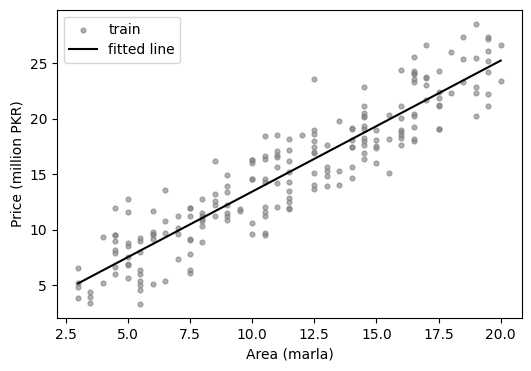

In [3]:
fig, ax = plt.subplots(figsize=(6, 4))
ax.scatter(train["area_marla"], train["price_million_pkr"], s=12, color="grey", alpha=0.6, label="train")
xs = np.linspace(train["area_marla"].min(), train["area_marla"].max(), 50).reshape(-1, 1)
ax.plot(xs, simple.predict(pd.DataFrame(xs, columns=["area_marla"])), color="black", label="fitted line")
ax.set_xlabel("Area (marla)")
ax.set_ylabel("Price (million PKR)")
ax.legend()
plt.show()

## 2. Multiple linear regression: all features
Model: `price = b0 + b1*area + b2*bedrooms + b3*bathrooms + b4*age + zone effects`.

In [4]:
target = "price_million_pkr"
features = [c for c in df.columns if c != target]
print("Features:", features)

multi = LinearRegression()
multi.fit(train[features], train[target])

report("Simple (area only)", val[target], simple.predict(val[["area_marla"]]))
report("Multiple (all features)", val[target], multi.predict(val[features]))

Features: ['area_marla', 'bedrooms', 'bathrooms', 'age_years', 'location_zone_Outskirts', 'location_zone_Suburban']


Simple (area only)           MAE=1.836  RMSE=2.331  R2=0.849
Multiple (all features)      MAE=1.271  RMSE=1.547  R2=0.934


In [5]:
coefs = pd.Series(multi.coef_, index=features).round(3)
print("Intercept:", round(multi.intercept_, 3))
print("\nCoefficients (change in price, in million PKR, per one unit of the feature):")
print(coefs)

Intercept: 4.478

Coefficients (change in price, in million PKR, per one unit of the feature):
area_marla                 0.925
bedrooms                   0.521
bathrooms                  0.623
age_years                 -0.061
location_zone_Outskirts   -3.706
location_zone_Suburban    -2.076
dtype: float64


Each coefficient is read as "the change in price for one extra unit of this feature while the others
stay the same". The zone columns compare against the zone that was dropped (Central).

In [6]:
# Predict a brand new house
new_house = pd.DataFrame([{
    "area_marla": 10, "bedrooms": 3, "bathrooms": 2, "age_years": 5,
    "location_zone_Outskirts": 0, "location_zone_Suburban": 1,
}])[features]
print(f"Predicted price: {multi.predict(new_house)[0]:.2f} million PKR")

Predicted price: 14.16 million PKR


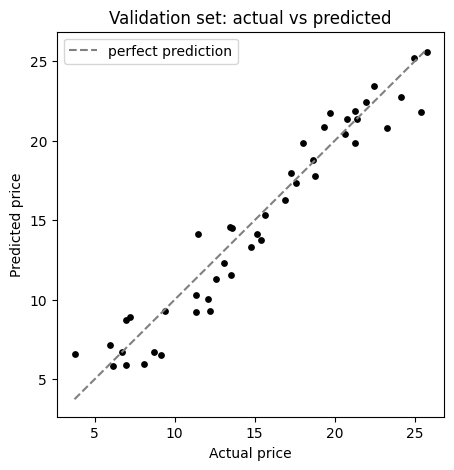

In [7]:
fig, ax = plt.subplots(figsize=(5, 5))
pred = multi.predict(val[features])
ax.scatter(val[target], pred, color="black", s=15)
lims = [val[target].min(), val[target].max()]
ax.plot(lims, lims, color="grey", linestyle="--", label="perfect prediction")
ax.set_xlabel("Actual price")
ax.set_ylabel("Predicted price")
ax.set_title("Validation set: actual vs predicted")
ax.legend()
plt.show()